# DQI for teacher–section timetabling: data → circuit → result

Same problem and CSV layout as [QMOS-Lab/ttqaoa](https://github.com/QMOS-Lab/ttqaoa) (QAOA), solved with
**Decoded Quantum Interferometry** (DQI). The quota constraint is excluded: it cannot be written as a
max-LINSAT row (see §2). Everything below calls the package modules; the notebook only glues and explains.

**References**
- [J] Jordan et al., *Optimization by Decoded Quantum Interferometry*, arXiv:2408.08292 v3 / Nature 646 (2025). §8.2 (general $\mathbb{F}_p$), Lemma 9.2 (tridiagonal), Thm 10.1 (imperfect decoder).
- [PL] PennyLane demo `tutorial_dqi` ($\mathbb{F}_2$ circuit, lookup-table decoder).
- [GC] Gao & Chang, arXiv:2604.15025 (bounds with per-weight decoder failure $\varepsilon_k$).
- [P] Patamawisut et al., arXiv:2504.18334 (explicit $\mathbb{F}_2$ circuits, Gauss–Jordan decoder).

## Notation, in timetable terms

| symbol | in this problem | insight |
|---|---|---|
| $n$ | number of sections | one variable each |
| $p$ | field size = smallest prime $\ge$ #teachers | values $\ge$ #teachers are dummy teachers |
| $y\in\mathbb{F}_p^n$ | a full timetable: $y_j$ = teacher of section $j$ | what the algorithm samples |
| $m$ | number of constraints (rows): conflicts + eligibility | more rows = harder, but also more signal |
| $b_i, F_i$ | row $i$: which sections it touches, and the allowed values of $b_i\cdot y$ | conflict: $y_a-y_b\ne0$; eligibility: $y_j\in E_j$ |
| $s(y)$ | number of satisfied rows of timetable $y$ | **higher is better**, max $=m$ |
| $\langle s\rangle/m$ | expected satisfied fraction of a sampled timetable | 1 = perfect; random $\approx 1-1/p$ for conflicts |
| $f(y)=2s-m$ | the paper's objective (satisfied minus violated) | same information as $s$, in $[-m,m]$ |
| $\ell$ | degree of $P$ = how many rows DQI "corrects" at once | higher = sharper bias, but limited by decoding |
| $w_k$ | weight of the degree-$k$ piece of the state | chosen to maximise $\langle s\rangle$; only $w_k^2$ matters |
| $e\in\mathbb{F}_p^m$ | an "error" = a small set of rows with a nonzero label each | $|e|=k$: $k$ rows flagged |
| $B^Te$ | syndrome of $e$: what the circuit can see | decoding = $B^Te\mapsto e$ |
| $d_{\text{code}}$ | min number of rows whose labels cancel ($B^Te=0$) = girth of the conflict graph | unique decoding iff $2\ell<d_{\text{code}}$; **larger is better** |
| $\varepsilon_k$ | fraction of weight-$k$ errors the decoder gets wrong | 0 = perfect; **smaller is better**; enters the lower bounds of [J Thm 10.1], [GC] |
| $\rho=r/p$ | probability a random $y$ satisfies one row | random baseline of $\langle s\rangle/m$ |
| $d=(p-2r)/\sqrt{r(p-r)}$ | row bias: $0$ for $\mathbb{F}_2$, $<0$ when rows are easy ($r>p/2$, e.g. conflicts), $>0$ when hard | shifts the diagonal of the tridiagonal matrix |
| $\lambda_{\max}$ | top eigenvalue of that matrix | directly gives the predicted $\langle s\rangle/m$; **higher is better** |


In [1]:
import sys
import numpy as np
from loguru import logger
logger.remove(); logger.add(sys.stderr, level="WARNING")   # keep the notebook quiet
np.set_printoptions(linewidth=140, precision=3, suppress=True)

from dqitt.problem import load, build, brute_force, code_distance, decoder_failure, all_x
from dqitt.dqi import theory_weights, tridiagonal, ideal_state, basis_states, expected_satisfied, sample
from dqitt.circuit import DQICircuit, row_coeffs, lookup_table
from dqitt import paths, viz
from pathlib import Path
out = Path("../reports/notebook"); out.mkdir(parents=True, exist_ok=True)

## 1. Data

`$DQITT_DATA/dqitt/mini` is a shrunken `16qubits` instance from ttqaoa: 8 sections in 4 slots, 3 teachers.
`SlotConflict.csv` says which slots overlap in time (A24–A25, A42–A52, and every slot with itself).
`InstructorSkill.csv` / `InstructorSlot.csv` give eligibility (threshold 5, as in ttqaoa). No `InstructorQuota.csv`.

teachers: ['t1', 't2', 't3']
0: AI1910  slot A24  eligible ['t1', 't2']
1: AI1911  slot A24  eligible ['t1', 't3']
2: AI1912  slot A25  eligible ['t1', 't2']
3: AI1913  slot A25  eligible ['t1', 't3']
4: AI1914  slot A42  eligible ['t1', 't2']
5: AI1915  slot A42  eligible ['t1', 't3']
6: AI1916  slot A52  eligible ['t1', 't2']
7: AI1917  slot A52  eligible ['t1', 't3']
conflicts (section pairs): [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3), (4, 5), (4, 6), (4, 7), (5, 6), (5, 7), (6, 7)]


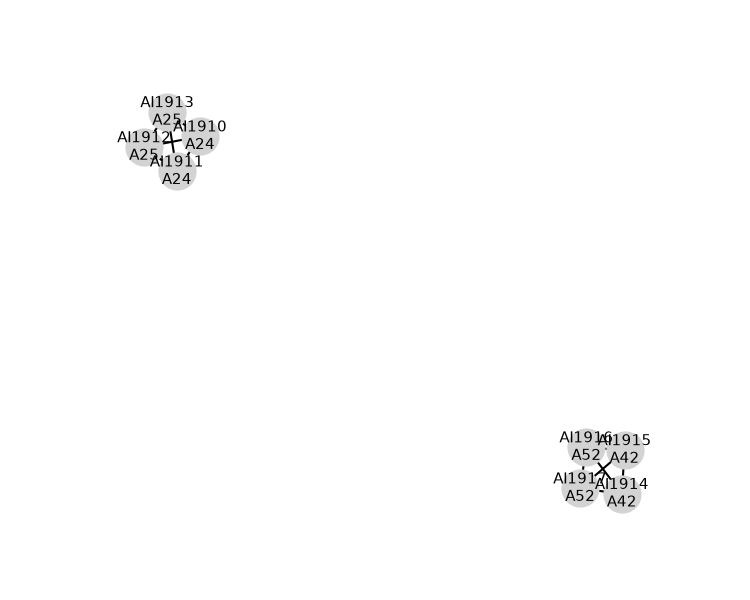

In [2]:
inst = load(paths.DATA / "dqitt" / "mini")
print("teachers:", inst.teachers)
for j, (s, slot, E) in enumerate(zip(inst.sections, inst.slots, inst.eligible)):
    print(f"{j}: {s:7s} slot {slot}  eligible {sorted(inst.teachers[t] for t in E)}")
print("conflicts (section pairs):", inst.conflicts)
viz.conflict_graph(inst, out / "conflict_graph.png")
from IPython.display import Image; Image(out / "conflict_graph.png")

## 2. Formulation: max-LINSAT over $\mathbb{F}_p$

One variable per section, $y_j \in \mathbb{F}_p$ = index of its teacher, with $p$ the smallest prime $\ge$ #teachers
(here $p=3$). Extra field elements would be dummy teachers. Each constraint is a row $b_i$ and an allowed set $F_i$:

$$\text{conflict }(a,b):\; y_a - y_b \in F_i = \mathbb{F}_p\setminus\{0\}, \qquad
\text{eligibility } j:\; y_j \in F_i = E_j .$$

Objective: maximise $s(y) = \#\{i : b_i\cdot y \in F_i\}$. This is exactly [J] Def. 2.1 (max-LINSAT), with
$f_i(z) = +1$ if $z\in F_i$ else $-1$ and $f = \sum_i f_i = 2s - m$.

Why quota is excluded: "teacher $t$ gets at most $q$ sections" counts how many $y_j$ equal $t$; that is not a
condition on a single linear form $b_i\cdot y$, so no row can express it. Quota would have to be handled
outside DQI (post-selection or a different encoding).

In [3]:
lin = build(inst)                     # eligibility=True (default); build(inst, eligibility=False) = conflict rows only
print(f"p={lin.p}  n={lin.n} variables  m={lin.m} rows")
print("B (first 12 rows = conflicts, then 8 eligibility rows):"); print(lin.B)
print("allowed values F_i per row:"); print(lin.F.astype(int))
opt, xs = brute_force(lin)
X = all_x(lin.p, lin.n)
print(f"optimum {opt}/{lin.m} attained by {len(xs)} assignments; uniformly random y satisfies {lin.count(X).mean():.3f} on average = {lin.count(X).mean()/lin.m:.4f} m")

p=3  n=8 variables  m=20 rows
B (first 12 rows = conflicts, then 8 eligibility rows):
[[1 2 0 0 0 0 0 0]
 [1 0 2 0 0 0 0 0]
 [1 0 0 2 0 0 0 0]
 [0 1 2 0 0 0 0 0]
 [0 1 0 2 0 0 0 0]
 [0 0 1 2 0 0 0 0]
 [0 0 0 0 1 2 0 0]
 [0 0 0 0 1 0 2 0]
 [0 0 0 0 1 0 0 2]
 [0 0 0 0 0 1 2 0]
 [0 0 0 0 0 1 0 2]
 [0 0 0 0 0 0 1 2]
 [1 0 0 0 0 0 0 0]
 [0 1 0 0 0 0 0 0]
 [0 0 1 0 0 0 0 0]
 [0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0]
 [0 0 0 0 0 1 0 0]
 [0 0 0 0 0 0 1 0]
 [0 0 0 0 0 0 0 1]]
allowed values F_i per row:
[[0 1 1]
 [0 1 1]
 [0 1 1]
 [0 1 1]
 [0 1 1]
 [0 1 1]
 [0 1 1]
 [0 1 1]
 [0 1 1]
 [0 1 1]
 [0 1 1]
 [0 1 1]
 [1 1 0]
 [1 0 1]
 [1 1 0]
 [1 0 1]
 [1 1 0]
 [1 0 1]
 [1 1 0]
 [1 0 1]]
optimum 18/20 attained by 64 assignments; uniformly random y satisfies 13.333 on average = 0.6667 m


Two sections of the same slot plus a conflicting slot form a triangle in the conflict graph, and each slot
clique here is a $K_4$. The optimum $18/20$ means one conflict per $K_4$ must be violated with 3 teachers
(4-chromatic graph), plus eligibility.

## 3. DQI in one page

**Idea** [J §2]. Instead of amplitudes uniform in $y$, prepare
$$|P(f)\rangle = \sum_{y\in\mathbb{F}_p^n} P(f(y))\,|y\rangle$$
for a degree-$\ell$ polynomial $P$. Measuring gives $y$ with probability $\propto P(f(y))^2$, biased toward large $f$.
Higher $\ell$ = sharper bias, but $\ell$ is limited by *decoding* (below).

**Basis** [J eq. 36–50]. Per row let $h_i(y)=[b_i\cdot y\in F_i]$, mean $\rho_i=|F_i|/p$, and the centred, unit-variance
$$\tilde g_i(y) = \frac{h_i(y)-\rho_i}{\sqrt{\rho_i(1-\rho_i)}}, \qquad s(y) = \sum_i \rho_i + \sum_i\sqrt{\rho_i(1-\rho_i)}\,\tilde g_i(y).$$
Define $|P_k\rangle = p^{-n/2}\binom{m}{k}^{-1/2}\sum_y e_k(\tilde g_1(y),\dots,\tilde g_m(y))\,|y\rangle$ with $e_k$ the
$k$-th elementary symmetric polynomial. Then $|P(f)\rangle = \sum_{k\le\ell} w_k |P_k\rangle$.

**Why this basis is preparable** [J eq. 48]. The $\mathbb{F}_p$ Fourier transform of $|P_k\rangle$ is
$$F^{\otimes n}|P_k\rangle = \binom{m}{k}^{-1/2}\sum_{e\in\mathbb{F}_p^m,\ |e|=k}\ \prod_{i:e_i\ne0} c_i(e_i)\ |B^{T}e\rangle,
\qquad c_i(e)=\tfrac1p\sum_{z}\tilde g_i(z)\,\omega_p^{-ez},$$
a superposition over weight-$k$ "error" vectors $e$, each mapped to its *syndrome* $B^Te$. The circuit prepares the
$e$-superposition, computes $B^Te$ into a fresh register, and must then **erase $e$ given $B^Te$**: syndrome
decoding of the code $\ker B^T$ with $\le\ell$ errors. Unique decoding needs $2\ell < d_{\text{code}}$.

**Code distance here.** $\ker B^T$ restricted to conflict rows is the cycle space of the conflict graph, so
$d_{\text{code}}=\text{girth}$; triangles give $d_{\text{code}}=3$ and $\ell\le1$ for unique decoding.

In [4]:
d = code_distance(lin)
print(f"code distance (min weight of nonzero e with B^T e = 0): {d}  ->  unique decoding for l <= {(d-1)//2}")
for l in (1, 2, 3):
    print(f"l={l}: eps_k (fraction of weight-k errors an ideal min-weight decoder cannot recover) = {decoder_failure(lin, l)}")

code distance (min weight of nonzero e with B^T e = 0): 3  ->  unique decoding for l <= 1
l=1: eps_k (fraction of weight-k errors an ideal min-weight decoder cannot recover) = [0. 0.]
l=2: eps_k (fraction of weight-k errors an ideal min-weight decoder cannot recover) = [0.    0.    0.474]
l=3: eps_k (fraction of weight-k errors an ideal min-weight decoder cannot recover) = [0.    0.    0.474 1.   ]


Reading the output: $d_{\text{code}}=3$ comes from any triangle (two sections in one slot plus a conflicting slot).
$\varepsilon_k=0$ for $k\le1$ means a single flagged row is always recognisable from its syndrome; at $k=2$ about half
the pairs of flagged rows are confused with a single row on the third edge of a triangle, and $k=3$ is hopeless.
These numbers set the ceiling on $\ell$ for a real circuit, independently of any decoder algorithm.

## 4. Choosing the weights $w_k$

**Paper's formula** [J Lemma 9.2]. If all $|F_i|=r$ and $2\ell+1<d_{\text{code}}$, the $|P_k\rangle$ are orthonormal and
$\sum_i\tilde g_i$ acts on them as the tridiagonal
$$A^{(m,\ell,d)}_{kk}=k\,d,\quad A_{k-1,k}=\sqrt{k(m-k+1)},\quad d=\frac{p-2r}{\sqrt{r(p-r)}},$$
so the best $w$ is the top eigenvector and
$\langle s\rangle/m = \tfrac rp + \tfrac{\sqrt{r(p-r)}}{p}\,\tfrac{\lambda_{\max}}{m}$ ([J eq. 129]).
The $d$ term is what distinguishes $\mathbb{F}_p$ from $\mathbb{F}_2$: it comes from $\tilde g_i^2 = 1 + d\,\tilde g_i$.

**Exact alternative** (`dqi.ideal_state`). For $p^n$ small we can build the $|P_k\rangle$ as vectors and maximise
$\langle\psi|s|\psi\rangle$ over $\psi\in\mathrm{span}\{P_k\}$ directly: generalized eigenproblem $Mw=\lambda Gw$
with $M_{kk'}=\langle P_k|s|P_{k'}\rangle$, $G_{kk'}=\langle P_k|P_{k'}\rangle$. This needs neither homogeneous $r$
nor orthogonality, so it is the reference for this problem.

In [5]:
rows = []
for l in (1, 2, 3):
    psi, X, w = ideal_state(lin, l)
    P, _ = basis_states(lin, l)
    G = P.T @ P
    conf = build(inst, eligibility=False)          # homogeneous r = p-1 -> theory applies
    psi_c, Xc, _ = ideal_state(conf, l)
    w_th, frac_th = theory_weights(conf.m, l, conf.p, conf.p - 1)
    rows.append((l, expected_satisfied(psi, lin, X)/lin.m, expected_satisfied(psi_c, conf, Xc)/conf.m, frac_th, np.abs(G - np.eye(l+1)).max()))
print(" l | exact <s>/m (full) | exact <s>/m (conflict only) | theory (conflict only) | max |G - I|")
for r in rows: print(f" {r[0]} |      {r[1]:.4f}        |          {r[2]:.4f}             |        {r[3]:.4f}          |  {r[4]:.3f}")

 l | exact <s>/m (full) | exact <s>/m (conflict only) | theory (conflict only) | max |G - I|
 1 |      0.7475        |          0.7500             |        0.7896          |  0.000
 2 |      0.8004        |          0.7957             |        0.8655          |  0.275
 3 |      0.8363        |          0.8167             |        0.9167          |  0.693


Columns: *exact (full)* is the reference for the actual problem; *exact (conflict only)* drops eligibility so the
paper's formula applies; *theory* is [J eq. 129]; *max $|G-I|$* measures how far the $|P_k\rangle$ are from orthonormal
(0 = the paper's assumptions hold, larger = collisions between error weights).

Even at $\ell=1$ the theory number is too high. Reason: on a triangle $a,b,c$ the three $\tilde g$ are dependent
($b_a+b_b+b_c=0$), so $\mathbb{E}[\tilde g_a\tilde g_b\tilde g_c]\ne0$ and $\langle P_1|\sum_i\tilde g_i|P_1\rangle$ is not
$d$. Lemma 9.2's condition $2\ell+1<d_{\text{code}}$ fails at $\ell=1$ when the girth is 3. The Gram matrix column
shows the $|P_k\rangle$ stop being orthonormal from $\ell=2$ (weight-2 errors collide with weight-1 through triangles).

## 5. Ideal DQI output on `mini`

The exact state is decoder-independent: it is what a perfect decoder would produce. Sample it and compare with random.

w = [0.506 0.756 0.414]   <s>/m = 0.8004


best sampled (18/20): {'AI1910': 't1', 'AI1911': 't1', 'AI1912': 't2', 'AI1913': 't3', 'AI1914': 't2', 'AI1915': 't3', 'AI1916': 't2', 'AI1917': 't1'}


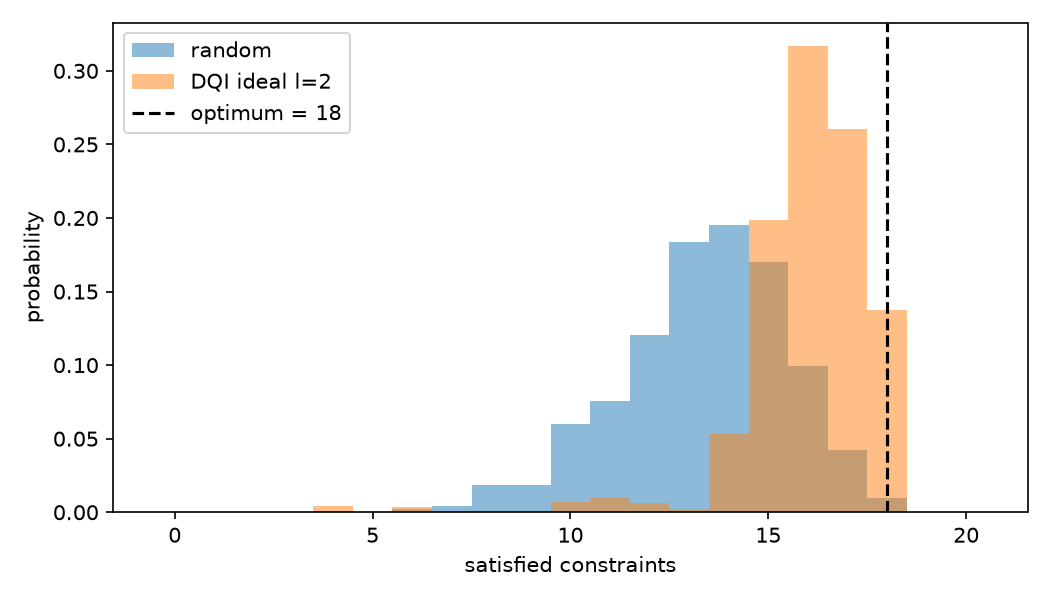

In [6]:
l = 2
psi, X, w = ideal_state(lin, l)
rng = np.random.default_rng(0)
samples = {"random": rng.integers(0, lin.p, (4000, lin.n)), f"DQI ideal l={l}": sample(psi, X, 4000, rng)}
print("w =", w, "  <s>/m =", round(expected_satisfied(psi, lin, X)/lin.m, 4))
best = max(samples[f"DQI ideal l={l}"], key=lin.count)
print(f"best sampled ({lin.count(best)}/{lin.m}):", {s: inst.teachers[t] for s, t in zip(inst.sections, best)})
viz.satisfied_histogram(lin, samples, opt, out / "histogram_mini.png"); Image(out / "histogram_mini.png")

Histogram: x-axis is $s(y)$ for each sampled timetable, y-axis its frequency. Mass shifted to the right = better;
the dashed line is the true optimum. $w$ is the normalised weight vector; $w_1$ dominating means most of the state is the
"one row corrected" piece. Sampling is exactly the measurement outcome distribution of the ideal circuit.

## 6. The circuit, on `tiny`

`circuit.py` implements the general-$\mathbb{F}_p$ circuit with $q=\lceil\log_2p\rceil$ qubits per symbol
(no such circuit exists in [P] or [PL], which are $\mathbb{F}_2$ only). Registers: `flags` ($m$), `error` ($m$ symbols),
`syndrome` ($n$ symbols), total $m + q(m+n)$ qubits, so only `$DQITT_DATA/dqitt/tiny` (3 sections, triangle, $m=6$, 24 qubits) fits.

| step | operation | how |
|---|---|---|
| 1 | flags $\leftarrow \sum_k w_k\,|\text{Dicke}_{m,k}\rangle$ | `StatePrep` (replaces weight register + controlled Dicke prep of [PL]) |
| 2 | flag$_i$ controls error$_i \leftarrow \sum_{e\ne0} c_i(e)|e\rangle$ | Householder unitary from $\lvert0\rangle$ |
| 3 | uncompute flags: flag$_i \mathrel{\oplus}= [\text{error}_i\ne0]$ | $X$ + zero-controlled $X$ |
| 4 | syndrome$_j \mathrel{+}= B_{ij}\,\text{error}_i \pmod p$ | permutation unitary on 2 symbols |
| 5 | decode: for each table row $(s,e)$, if syndrome $=s$ subtract $e$ | multi-controlled shift |
| 6 | $\mathrm{QFT}_p$ on each syndrome symbol, measure $\to y$ | $p\times p$ DFT padded to $2^q$ |

Step 5 is a lookup table with $\sum_{k\le\ell}\binom mk(p-1)^k$ rows: fine for tiny, hopeless at scale (that is where a
BP / information-set decoder comes in, [J §5], [GC]).

In [7]:
tiny = build(load(paths.DATA / "dqitt" / "tiny"))
print(f"tiny: p={tiny.p} n={tiny.n} m={tiny.m}, optimum {brute_force(tiny)[0]}/{tiny.m}, code distance {code_distance(tiny)}")
print("local Fourier coefficients c_i(e) of row 0 (conflict) and row 3 (eligibility {t1,t2}):")
print(row_coeffs(tiny, 0)); print(row_coeffs(tiny, 3))
for l in (1, 2):
    psi, X, w = ideal_state(tiny, l)
    circ = DQICircuit(tiny, l, w, device="lightning.qubit")
    pr = circ.probs_x()
    print(f"l={l}: {circ.n_wires} wires, LUT rows {len(circ.table)}, eps={decoder_failure(tiny, l)} | "
          f"max |p_circuit - p_ideal| = {np.abs(pr - np.abs(psi)**2).max():.1e} | "
          f"<s>/m circuit {(pr*tiny.count(X)).sum()/tiny.m:.4f} vs ideal {expected_satisfied(psi, tiny, X)/tiny.m:.4f}")

tiny: p=3 n=3 m=6, optimum 6/6, code distance 3
local Fourier coefficients c_i(e) of row 0 (conflict) and row 3 (eligibility {t1,t2}):
[ 0.   +0.j -0.707-0.j -0.707-0.j]
[0.   +0.j    0.354-0.612j 0.354+0.612j]


l=1: 24 wires, LUT rows 12, eps=[0. 0.] | max |p_circuit - p_ideal| = 5.6e-17 | <s>/m circuit 0.8114 vs ideal 0.8114


l=2: 24 wires, LUT rows 26, eps=[0. 0. 1.] | max |p_circuit - p_ideal| = 1.3e-01 | <s>/m circuit 0.7838 vs ideal 0.9184


Reading the output: $c_i(e)$ are the amplitudes put on the error symbol of row $i$ (value $e\in\{1,2\}$); a conflict row
is symmetric ($c(1)=c(2)$, real), an eligibility row is not (complex, conjugate pair), and $\sum_e|c_i(e)|^2=1$.
*max $|p_{\text{circuit}}-p_{\text{ideal}}|$* is the largest gap between the two output distributions over all $p^n$ timetables:
$\sim10^{-16}$ = identical, $\sim10^{-1}$ = decoder failures are visible.

At $\ell=1$ the circuit reproduces the ideal state to machine precision. At $\ell=2$ every weight-2 error collides
with a weight-1 error through the triangle ($\varepsilon_2=1$): the decoder leaves garbage in the error register,
those branches decohere, and the output is worse than the ideal state, which is the brief's negative result
seen in an actual simulation.

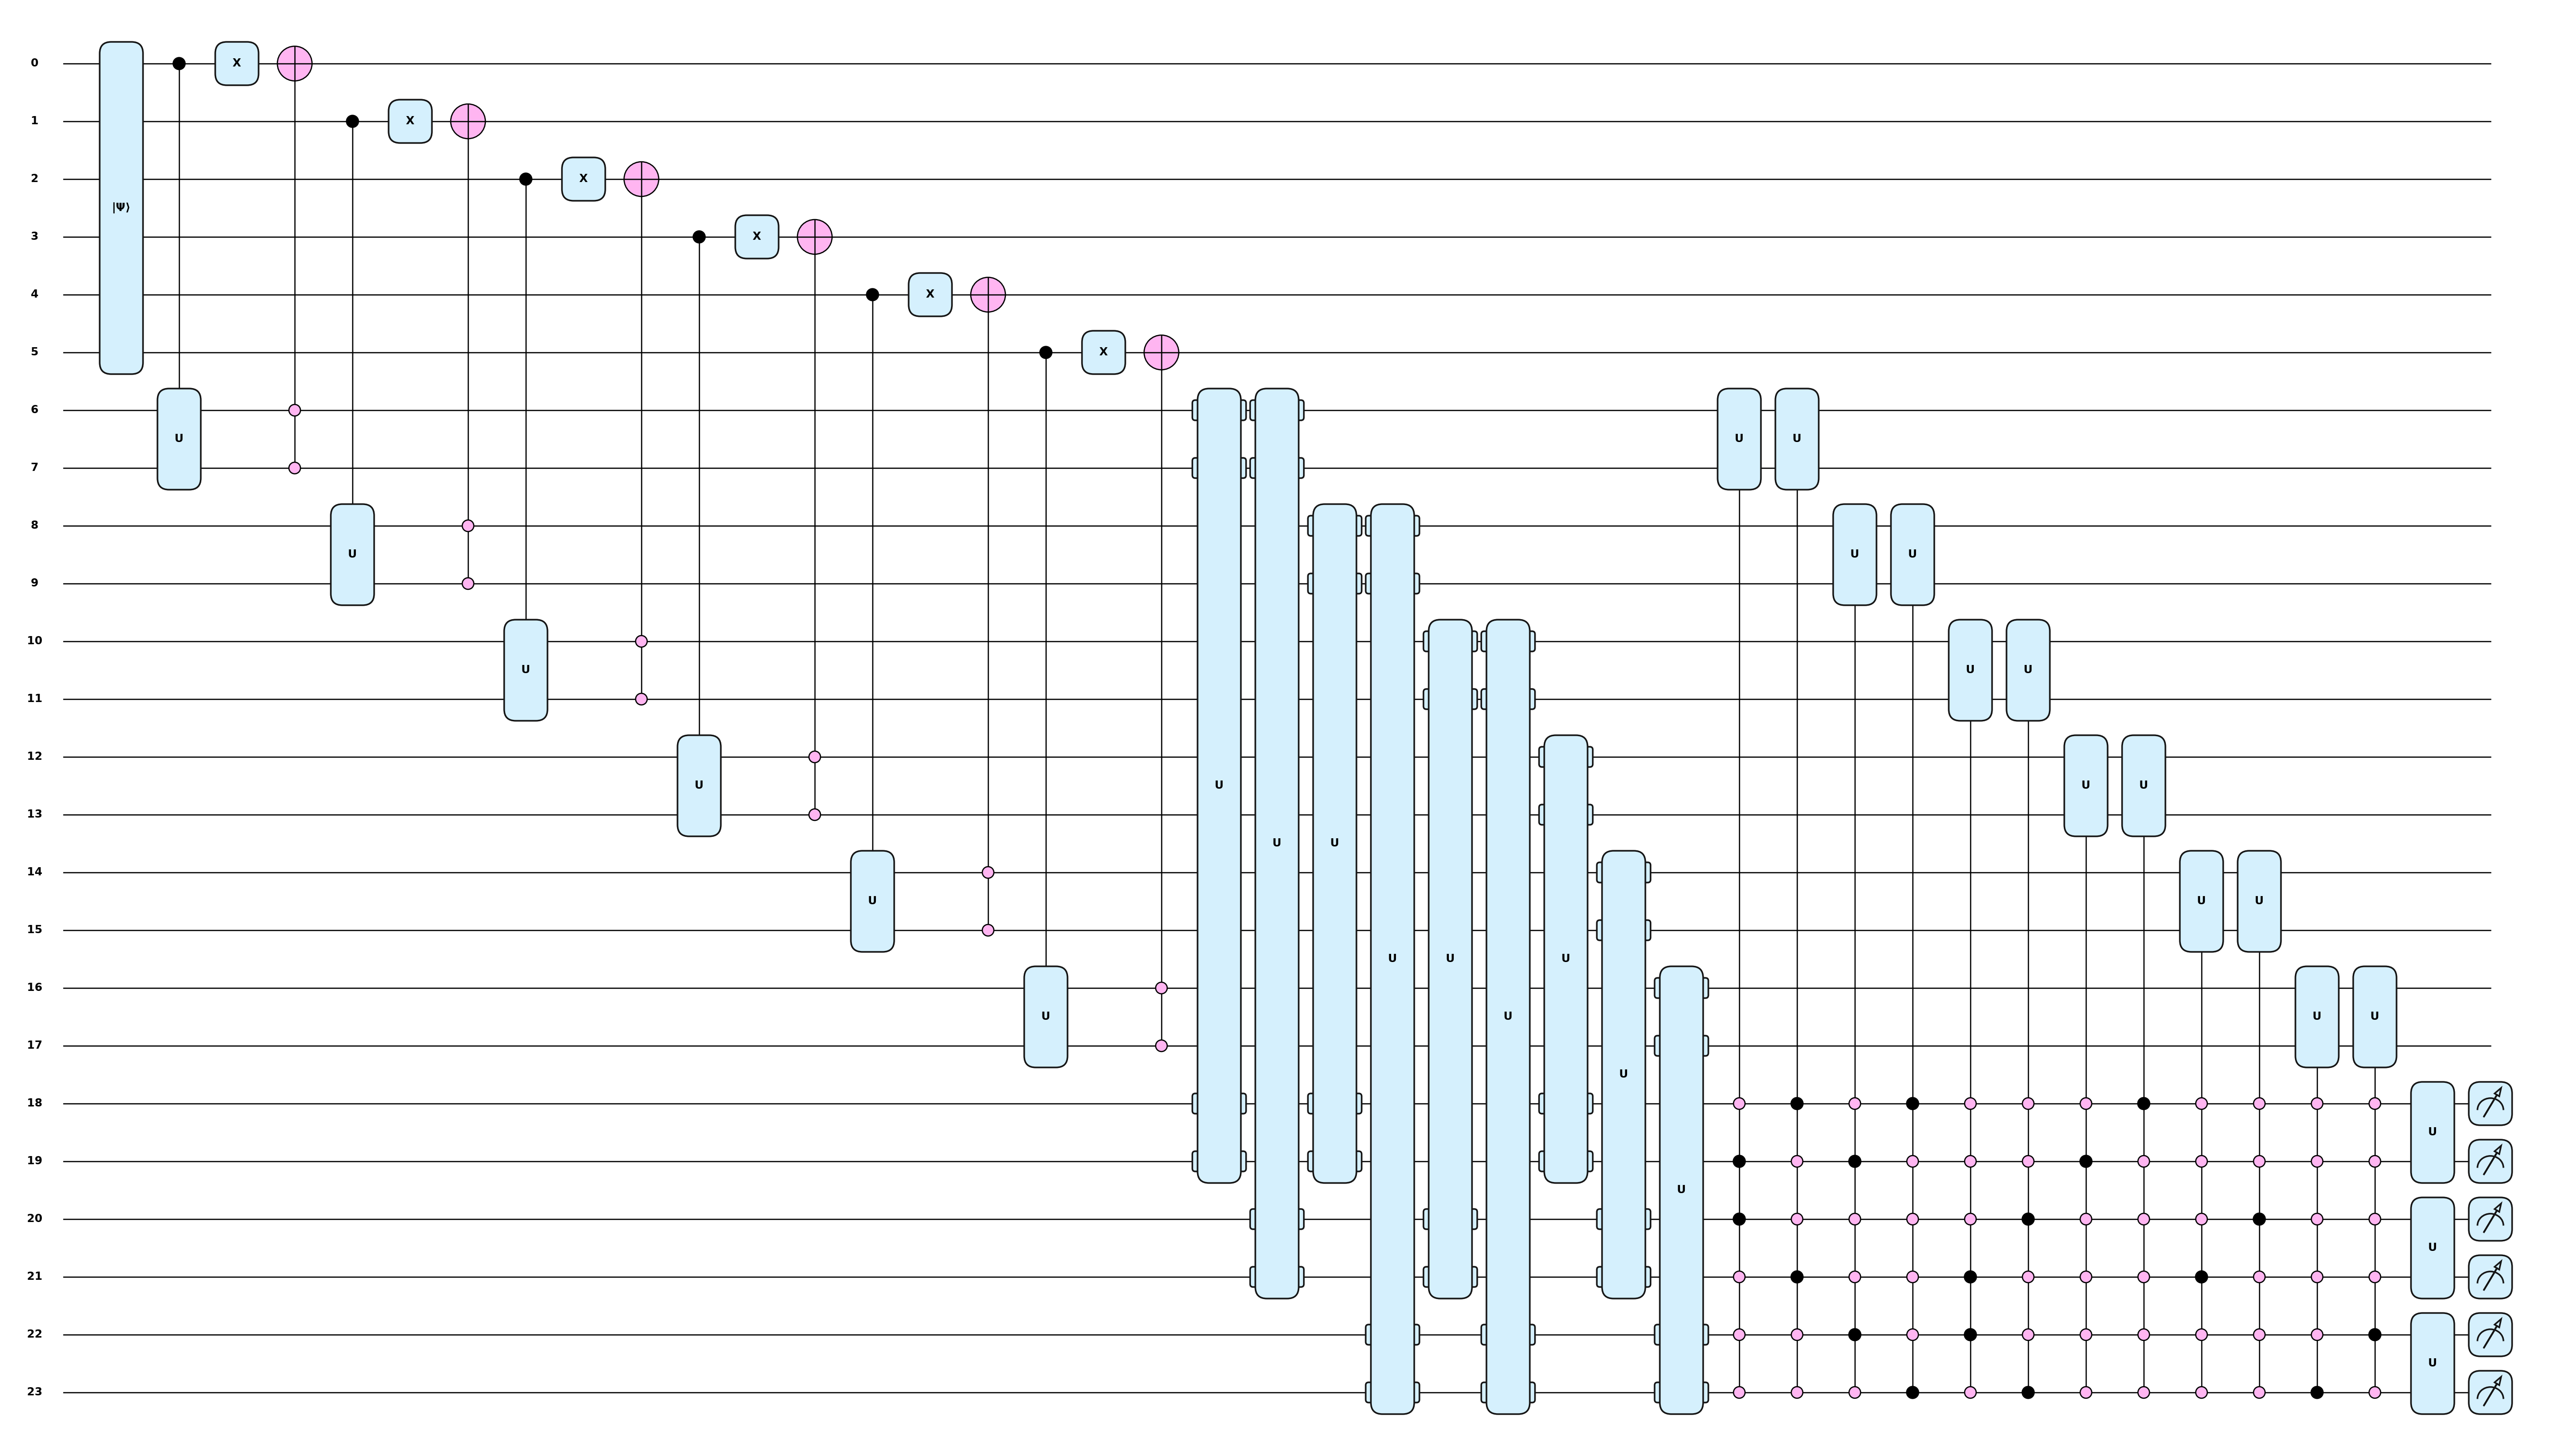

In [8]:
psi, X, w = ideal_state(tiny, 1)
circ = DQICircuit(tiny, 1, w, device="lightning.qubit")
viz.circuit(circ, out / "circuit_tiny.png"); Image(out / "circuit_tiny.png")

Reading the drawing top to bottom: wires 0–5 flags, 6–17 error symbols (2 qubits each), 18–23 syndrome symbols.
Left to right: state prep, six (controlled prep, $X$, zero-controlled $X$) blocks, the $B^T$ adders, the lookup
decoder (many-controlled shifts on the syndrome register), then three $\mathrm{QFT}_3$ boxes and measurement.

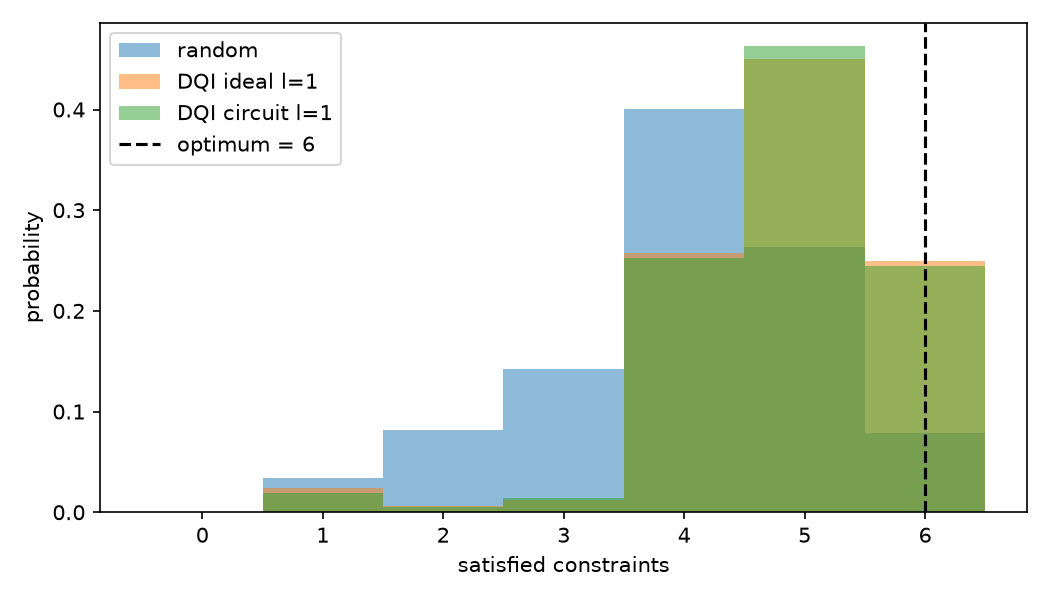

In [9]:
samples_t = {"random": rng.integers(0, tiny.p, (4000, tiny.n)),
             "DQI ideal l=1": sample(psi, X, 4000, rng),
             "DQI circuit l=1": X[rng.choice(len(X), 4000, p=circ.probs_x())]}
viz.satisfied_histogram(tiny, samples_t, brute_force(tiny)[0], out / "histogram_tiny.png"); Image(out / "histogram_tiny.png")

## 7. Where this leaves the research

- Formulation and ideal DQI work end to end; eligibility is expressible, quota is not.
- The structural obstacle is the girth-3 conflict graph: unique decoding stops at $\ell=1$, and [J]'s closed-form
  prediction is already optimistic there. Gains over random are real but modest at feasible $\ell$
  (mini: $0.667 \to 0.75$ at $\ell=1$, $0.80$ at $\ell=2$ ideal).
- Going beyond $\ell=1$ requires an imperfect decoder and its measured $\varepsilon_k$ ([J Thm 10.1], [GC Thm 3.1]).
  Next step: a scalable decoder (information-set / belief propagation over $\mathbb{F}_p$) in `decoder.py`, used
  classically to estimate $\varepsilon_k$ on the full ttqaoa instances.